# Análisis de sensibilidad: diseño 2^k

Se quiere saber **qué factores cambian el ahorro que dan los descuentos por cantidad**.

- Hay 10 factores; cada uno toma dos valores: **bajo (−1)** y **alto (+1)**. Se prueban **todas** las combinaciones: 2^10 = 1,024 corridas.
- En cada corrida se resuelven EOQ, (Q,R) y (S,T), sin y con descuento, con las **mismas funciones** del notebook principal.
- **Respuesta:** ahorro por usar los descuentos, en %:

$$\text{ahorro} = 100\times\frac{G_{\text{sin descuento}}-G_{\text{con descuento}}}{G_{\text{sin descuento}}}$$

- **Etapa 1 (screening):** efectos e interacciones de a dos de los 10 factores, para escoger los importantes (efecto mayor a 1 punto porcentual, p.p.).
- **Etapa 2:** solo los factores importantes, con **todas** sus interacciones (dobles, triples, ...). Se usan las mismas corridas: los factores que no importan hacen de repeticiones, así que el ANOVA tiene un error de verdad (proyección del diseño).
- **Robustez:** todo se repite con tres bases: Primer tramo (gana el primer tramo), Tramo intermedio (gana un tramo intermedio) y Último tramo (Buden), con los datos reales de Buden, donde gana el último tramo.

### 1. Cargar las funciones del notebook principal
`%run` corre el notebook principal completo (tarda cerca de un minuto) para tener sus funciones y los datos de Buden. `%%capture` esconde lo que imprime. El notebook principal no se modifica.

In [1]:
%%capture
# %%capture esconde las tablas y gráficas que imprime el notebook principal
%run modelos_inventario.ipynb
# %run corre el notebook principal para tener sus funciones (resolver_eoq..., resolver_qr..., resolver_st...) y los datos de Buden

In [2]:
import itertools                          # itertools.product arma todas las combinaciones de -1 y +1
from pathlib import Path                  # Path maneja rutas de carpetas
import numpy as np                        # numpy: repartir valores parejo (linspace) y promedios
import pandas as pd                       # pandas: tablas (DataFrame) y exportar a Excel
import matplotlib.pyplot as plt           # gráficas
import statsmodels.api as sm              # statsmodels: tabla ANOVA (igual que en la clase de diseño de experimentos)
from statsmodels.formula.api import ols   # ols ajusta el modelo escrito como fórmula: "respuesta ~ factores"
from scipy import stats                   # stats.probplot hace la gráfica Q-Q de los residuales

carpeta_sensibilidad = Path("graficas_sensibilidad")   # carpeta aparte, para que estas gráficas no se metan en el reporte del principal
carpeta_sensibilidad.mkdir(exist_ok=True)               # se crea si todavía no existe
modelos = {"eoq": "EOQ", "qr": "(Q,R)", "st": "(S,T)"}  # clave y nombre de cada modelo

### 2. Las tres bases
Las tres usan los costos de Buden; solo cambia la tabla de descuentos.

| Base | Descuentos | Límites | Tramo que gana |
|---|---|---|---|
| Último tramo (Buden) | 0 / 2 / 5 / 8 % | 4,000 / 9,000 / 15,000 | el último |
| Tramo intermedio | 0 / 1 / 2.5 / 4 % (la mitad) | 8,000 / 18,000 / 30,000 (el doble) | el segundo |
| Primer tramo | 0 / 1 / 2.5 / 4 % (la mitad) | 12,000 / 27,000 / 45,000 (el triple) | el primero (no conviene el descuento) |

In [3]:
precio_buden = datos_empresa["costo_unitario"]                      # $3,900: precio de lista de Buden


def tabla_base_devuelve_tramos(descuentos, limites, precio):        # arma una tabla de descuentos a partir de listas
    """Tabla [(desde, precio), ...] con los descuentos y límites dados (el primer tramo empieza en 0)."""
    return [(desde, precio * (1 - d)) for desde, d in zip([0] + limites, descuentos)]   # cada tramo: (desde, precio con descuento)


bases = {                                                          # las tres bases del análisis
    "buden": {"nombre": "Último tramo (Buden)",                                   # base 1: los datos reales
              "tabla": tramos_empresa},                             # su tabla real (0/2/5/8 %; 4,000/9,000/15,000)
    "intermedio": {"nombre": "Tramo intermedio",                   # base 2: gana un tramo de la mitad
                   "tabla": tabla_base_devuelve_tramos([0, 0.01, 0.025, 0.04], [8_000, 18_000, 30_000], precio_buden)},   # descuentos a la mitad, límites al doble
    "primero": {"nombre": "Primer tramo",                          # base 3: gana el primer tramo
                "tabla": tabla_base_devuelve_tramos([0, 0.01, 0.025, 0.04], [12_000, 27_000, 45_000], precio_buden)},     # descuentos a la mitad, límites al triple
}   # fin del diccionario
for base in bases.values():                                         # de cada tabla se sacan los números que usa la regla
    tabla = base["tabla"]                                           # la tabla de la base
    base["descuento_max"] = 1 - tabla[-1][1] / tabla[0][1]          # descuento del último tramo
    base["primer_limite"], base["ultimo_limite"] = tabla[1][0], tabla[-1][0]   # primer y último límite
    base["tramos"] = len(tabla)                                     # número de tramos (4 en las tres)

### 3. Factores y niveles
Regla: **bajo = base ÷ 2** y **alto = base × 2**. La única excepción es el número de tramos (3 y 8): 8 es 4 × 2, y 3 es el mínimo con el que existen un primer y un último límite. Los costos (lead time, variabilidad, K, i, λ, p y c) son los de Buden en las tres bases.

In [4]:
def niveles_de_una_base_devuelve_diccionario(base):                 # niveles (bajo, alto) de cada factor para una base
    """Aplica la regla ÷2 y ×2 a la base. Devuelve {factor: (bajo, alto)}."""
    d = datos_empresa                                               # costos de Buden (iguales en las tres bases)
    variabilidad = d["desviacion"] / d["demanda"]                   # sigma / lambda de Buden (24 %)
    return {                                                        # factor: (bajo, alto)
        "tramos": (3, 8),                                           # número de tramos
        "descuento": (base["descuento_max"] / 2, base["descuento_max"] * 2),          # descuento del último tramo
        "limites": ((base["primer_limite"] / 2, base["ultimo_limite"] / 2),            # límites bajos (primero, último)
                    (base["primer_limite"] * 2, base["ultimo_limite"] * 2)),           # límites altos
        "entrega": (d["lead_time"] / 2, d["lead_time"] * 2),        # lead time (meses)
        "variabilidad": (variabilidad / 2, variabilidad * 2),       # sigma / lambda
        "costo_pedido": (d["costo_pedido"] / 2, d["costo_pedido"] * 2),               # K
        "tasa_manejo": (d["tasa_manejo"] / 2, d["tasa_manejo"] * 2),                   # i mensual
        "demanda": (d["demanda"] / 2, d["demanda"] * 2),            # lambda
        "costo_faltante": (d["costo_faltante"] / 2, d["costo_faltante"] * 2),         # p
        "precio": (d["costo_unitario"] / 2, d["costo_unitario"] * 2),                  # c (precio de lista)
    }   # fin del diccionario


factores = list(niveles_de_una_base_devuelve_diccionario(bases["buden"]))   # los nombres de los 10 factores, en orden
for clave, base in bases.items():                                   # muestra los niveles de cada base
    print(f"\n--- {base['nombre']} ---")                           # título
    for factor, (bajo, alto) in niveles_de_una_base_devuelve_diccionario(base).items():   # cada factor
        print(f"{factor:15s} bajo = {bajo}   alto = {alto}")         # imprime sus dos niveles


--- Último tramo (Buden) ---
tramos          bajo = 3   alto = 8
descuento       bajo = 0.03999999999999998   alto = 0.15999999999999992
limites         bajo = (2000.0, 7500.0)   alto = (8000, 30000)
entrega         bajo = 0.08333333333333333   alto = 0.3333333333333333
variabilidad    bajo = 0.12178411944614306   alto = 0.48713647778457225
costo_pedido    bajo = 75000.0   alto = 300000
tasa_manejo     bajo = 0.012499999999999999   alto = 0.049999999999999996
demanda         bajo = 2662.7608695652175   alto = 10651.04347826087
costo_faltante  bajo = 1500.0   alto = 6000
precio          bajo = 1950.0   alto = 7800

--- Tramo intermedio ---
tramos          bajo = 3   alto = 8
descuento       bajo = 0.020000000000000018   alto = 0.08000000000000007
limites         bajo = (4000.0, 15000.0)   alto = (16000, 60000)
entrega         bajo = 0.08333333333333333   alto = 0.3333333333333333
variabilidad    bajo = 0.12178411944614306   alto = 0.48713647778457225
costo_pedido    bajo = 75000.0   al

### 4. Funciones de una corrida
- `tramos_de_descuento_devuelve_lista` arma la tabla de descuentos de una corrida: el primer tramo siempre en 0 %, y los límites y descuentos intermedios repartidos parejo entre el primero y el último.
- `ahorros_de_una_corrida_devuelve_diccionario` resuelve los tres modelos sin y con descuento y devuelve los costos, el ahorro % y el tramo que gana.

In [5]:
def tramos_de_descuento_devuelve_lista(numero_tramos, descuento_maximo, primer_limite, ultimo_limite, precio_lista):   # arma la tabla de descuentos
    """Tabla de descuentos con límites y descuentos repartidos parejo. Devuelve [(desde, precio), ...]."""
    limites = [0] + list(np.linspace(primer_limite, ultimo_limite, numero_tramos - 1))   # el primer tramo empieza en 0; los demás límites van parejo del primero al último
    descuentos = np.linspace(0, descuento_maximo, numero_tramos)                          # de 0 % (primer tramo) al descuento máximo (último tramo), en pasos iguales
    return [(desde, precio_lista * (1 - d)) for desde, d in zip(limites, descuentos)]   # cada tramo: (desde, precio con su descuento)


def ahorros_de_una_corrida_devuelve_diccionario(datos_corrida, tramos, paso=1 / 30):   # resuelve los 3 modelos sin y con descuento
    """Costo sin y con descuento de EOQ, (Q,R) y (S,T), el ahorro % y el tramo ganador de cada uno."""
    d = datos_corrida                                                               # nombre corto
    sin_precio = {k: v for k, v in d.items() if k != "costo_unitario"}            # los modelos con descuento no reciben precio: lo dan los tramos
    precios = [p for _, p in tramos]                                                # precio de cada tramo (para saber cuál gana)

    _, _, _, g_eoq_sin = resolver_eoq_sin_desc_devuelve_Q_T_R_G(d["demanda"], d["costo_pedido"], d["costo_unitario"],   # EOQ sin descuento
                                                              d["tasa_manejo"], d["lead_time"])   # (solo se usa el costo G)
    eoq_con, _ = resolver_eoq_con_desc_devuelve_mejor_y_candidatos(d["demanda"], d["costo_pedido"], tramos,   # EOQ con descuento
                                                                  d["tasa_manejo"], d["lead_time"])   # (solo se usa el ganador)
    g_qr_sin = resolver_qr_sin_desc_devuelve_solucion_con_iteraciones(**d)["costos"]["total"]                 # (Q,R) sin descuento
    qr_con, _ = resolver_qr_con_desc_devuelve_mejor_y_candidatos(tramos=tramos, **sin_precio)                 # (Q,R) con descuento
    g_st_sin = resolver_st_sin_desc_devuelve_solucion_con_T_probados(**d, paso=paso)["costos"]["total"]       # (S,T) sin descuento
    st_con, _ = resolver_st_con_desc_devuelve_mejor_y_candidatos(tramos=tramos, **sin_precio, paso=paso)      # (S,T) con descuento

    costos = {"eoq": (g_eoq_sin, eoq_con["costo"], eoq_con["precio"]),            # (costo sin, costo con, precio ganador) de cada modelo
              "qr": (g_qr_sin, qr_con["costos"]["total"], qr_con["precio"]),        # (Q,R)
              "st": (g_st_sin, st_con["costos"]["total"], st_con["precio"])}        # (S,T)
    resultado = {}                                                                  # aquí se guarda todo
    for modelo, (g_sin, g_con, precio_ganador) in costos.items():                   # para cada modelo
        resultado[f"G_sin_{modelo}"] = g_sin                                        # costo sin descuento
        resultado[f"G_con_{modelo}"] = g_con                                        # costo con descuento
        resultado[f"ahorro_{modelo}"] = 100 * (g_sin - g_con) / g_sin               # ahorro % = (sin - con) / sin
        resultado[f"tramo_{modelo}"] = precios.index(precio_ganador) + 1            # tramo que gana (1 = el primero)
    return resultado   # devuelve costos, ahorros y tramos ganadores

**Chequeo de las bases:** con la tabla exacta de cada base se calcula el ahorro y el tramo que gana. Para Buden debe dar el ahorro del caso de aplicación (EOQ 6.29 %, (Q,R) 6.41 %, (S,T) 5.77 %).

In [6]:
for clave, base in bases.items():                                   # una corrida con la tabla exacta de cada base
    r = ahorros_de_una_corrida_devuelve_diccionario(datos_empresa, base["tabla"])   # costos de Buden con la tabla de la base
    texto = "   ".join(f"{modelos[m]}: ahorro {miles(r[f'ahorro_{m}'], 2)} %, gana el tramo {r[f'tramo_{m}']}" for m in modelos)   # resumen por modelo
    print(f"{base['nombre']:17s} {texto}")                          # imprime el chequeo de la base

Último tramo (Buden) EOQ: ahorro 6.29 %, gana el tramo 4   (Q,R): ahorro 6.41 %, gana el tramo 4   (S,T): ahorro 5.77 %, gana el tramo 4


Tramo intermedio  EOQ: ahorro 0.55 %, gana el tramo 2   (Q,R): ahorro 0.61 %, gana el tramo 2   (S,T): ahorro 0.24 %, gana el tramo 2


Primer tramo      EOQ: ahorro 0.00 %, gana el tramo 1   (Q,R): ahorro 0.00 %, gana el tramo 1   (S,T): ahorro 0.00 %, gana el tramo 1


### 5. Las 1,024 corridas de cada base
Cada fila es una combinación de −1 (bajo) y +1 (alto) para los 10 factores. Con esos valores se arman los datos y la tabla de descuentos de la corrida y se calcula el ahorro de cada modelo.

In [7]:
combinaciones = list(itertools.product([-1, 1], repeat=len(factores)))   # las 2^10 = 1,024 combinaciones de -1 y +1
diseno = pd.DataFrame(combinaciones, columns=factores)                   # una fila por corrida, una columna por factor


def corridas_de_una_base_devuelve_tabla(base):                           # corre las 1,024 combinaciones de una base
    """Resuelve todas las corridas de una base. Devuelve la tabla: factores (-1/+1) + costos + ahorros + tramos."""
    niveles = niveles_de_una_base_devuelve_diccionario(base)             # niveles de esta base
    filas = []                                                           # aquí se guarda el resultado de cada corrida
    for _, corrida in diseno.iterrows():                                 # recorre las 1,024 corridas
        v = {f: niveles[f][0] if corrida[f] == -1 else niveles[f][1] for f in factores}   # valor real de cada factor (-1 = bajo, +1 = alto)
        datos_corrida = {"demanda": v["demanda"],                        # lambda
                         "desviacion": v["variabilidad"] * v["demanda"], # sigma = (sigma / lambda) * lambda
                         "costo_pedido": v["costo_pedido"],              # K
                         "costo_unitario": v["precio"],                  # c: precio de lista (sin descuento)
                         "tasa_manejo": v["tasa_manejo"],                # i
                         "costo_faltante": v["costo_faltante"],          # p
                         "lead_time": v["entrega"]}                      # tau
        primer_limite, ultimo_limite = v["limites"]                      # los dos límites de esta corrida
        tramos = tramos_de_descuento_devuelve_lista(v["tramos"], v["descuento"], primer_limite, ultimo_limite, v["precio"])   # tabla de descuentos
        filas.append(ahorros_de_una_corrida_devuelve_diccionario(datos_corrida, tramos))   # resuelve y guarda
    return pd.concat([diseno, pd.DataFrame(filas)], axis=1)              # tabla final de la base


resultados = {clave: corridas_de_una_base_devuelve_tabla(base) for clave, base in bases.items()}   # las corridas de las tres bases
for clave, base in bases.items():                                        # resumen del ahorro en cada base
    print(f"\n--- {base['nombre']} ---")                                # título
    print(resultados[clave][[f"ahorro_{m}" for m in modelos]].describe().round(2).to_string())   # promedio, mínimo y máximo del ahorro


--- Último tramo (Buden) ---
       ahorro_eoq  ahorro_qr  ahorro_st
count     1024.00    1024.00    1024.00
mean         7.42       7.54       7.10
std          6.14       6.16       6.07
min          0.00       0.00       0.00
25%          1.96       1.96       1.86
50%          3.96       3.96       3.92
75%         14.62      14.81      14.18
max         15.93      15.94      15.91

--- Tramo intermedio ---
       ahorro_eoq  ahorro_qr  ahorro_st
count     1024.00    1024.00    1024.00
mean         2.14       2.22       1.92
std          2.70       2.74       2.56
min          0.00       0.00       0.00
25%          0.00       0.00       0.00
50%          0.77       0.87       0.60
75%          4.19       4.20       3.79
max          7.93       7.93       7.92

--- Primer tramo ---
       ahorro_eoq  ahorro_qr  ahorro_st
count     1024.00    1024.00    1024.00
mean         1.61       1.70       1.40
std          2.34       2.39       2.17
min          0.00       0.00       0.00
25

### 6. Etapa 1: screening
Modelo con los 10 efectos y las 45 interacciones de a dos (`(...)**2`); las interacciones de 3 o más factores quedan como error. **Efecto = 2 × coeficiente**: cuánto cambia el ahorro, en puntos porcentuales (p.p.), al pasar el factor de bajo a alto. Un factor es **importante** si su efecto es mayor a 1 p.p.

In [8]:
formula_factores = " + ".join(factores)                                  # "tramos + descuento + limites + ..."


def etapa1_screening_devuelve_efectos_anova_e_importantes(tabla, respuesta):   # screening de una respuesta
    """Efectos e interacciones dobles. Devuelve (efectos con valor p, tabla ANOVA, factores importantes)."""
    modelo = ols(f"{respuesta} ~ ({formula_factores})**2", data=tabla).fit()   # 10 efectos + 45 interacciones de a dos
    anova = sm.stats.anova_lm(modelo, typ=2)                             # tabla ANOVA (igual que en la clase)
    efectos = pd.DataFrame({"efecto (p.p.)": modelo.params.drop("Intercept") * 2})   # efecto = 2 * coeficiente
    efectos["valor p"] = anova["PR(>F)"].reindex(efectos.index)          # valor p de cada término
    efectos = efectos.reindex(efectos["efecto (p.p.)"].abs().sort_values(ascending=False).index)   # de mayor a menor efecto
    importantes = [f for f in factores if abs(efectos.loc[f, "efecto (p.p.)"]) > 1]   # factores con efecto mayor a 1 p.p.
    if not importantes:                                                  # si ninguno pasa de 1 p.p....
        importantes = [max(factores, key=lambda f: abs(efectos.loc[f, "efecto (p.p.)"]))]   # ...se toma el más grande
    return efectos, anova, importantes   # devuelve los efectos, la tabla y los importantes


etapa1 = {(b, m): etapa1_screening_devuelve_efectos_anova_e_importantes(resultados[b], f"ahorro_{m}")   # screening de cada base y modelo
          for b in bases for m in modelos}                               # 3 bases x 3 modelos
for b, base in bases.items():                                            # muestra los efectos principales de cada base
    tabla = pd.DataFrame({modelos[m]: etapa1[(b, m)][0]["efecto (p.p.)"].reindex(factores) for m in modelos})   # efectos de los 10 factores
    print(f"\n--- {base['nombre']}: efecto de cada factor (p.p.) ---")  # título
    print(tabla.round(2).to_string())                                    # tabla de efectos
    for m in modelos:                                                    # factores importantes de cada modelo
        print(f"   importantes en {modelos[m]}: {etapa1[(b, m)][2]}")    # lista de importantes


--- Último tramo (Buden): efecto de cada factor (p.p.) ---
                  EOQ  (Q,R)  (S,T)
tramos          -0.48  -0.50  -0.43
descuento       10.41  10.51  10.21
limites         -3.33  -3.27  -3.44
entrega          0.00   0.08   0.12
variabilidad     0.00   0.14  -0.36
costo_pedido     0.53   0.48   0.68
tasa_manejo     -2.67  -2.52  -2.78
demanda          2.67   2.68   2.61
costo_faltante  -0.00  -0.03  -0.32
precio          -0.53  -0.45  -0.36
   importantes en EOQ: ['descuento', 'limites', 'tasa_manejo', 'demanda']
   importantes en (Q,R): ['descuento', 'limites', 'tasa_manejo', 'demanda']
   importantes en (S,T): ['descuento', 'limites', 'tasa_manejo', 'demanda']

--- Tramo intermedio: efecto de cada factor (p.p.) ---
                 EOQ  (Q,R)  (S,T)
tramos         -0.52  -0.54  -0.43
descuento       3.27   3.35   3.02
limites        -2.19  -2.24  -2.10
entrega        -0.00   0.05   0.07
variabilidad    0.00   0.09  -0.24
costo_pedido    0.38   0.36   0.45
tasa_manejo    -1

### 7. Etapa 2: los factores importantes con todas sus interacciones
Con las mismas corridas se ajusta un modelo solo con los factores importantes y **todas** sus interacciones (`(...)**k`, k = número de importantes). Las corridas quedan agrupadas por las combinaciones de los factores importantes; dentro de cada grupo cambian los demás factores, así que no son repeticiones: lo que el modelo no explica es el efecto de esos factores, no ruido. Las conclusiones se basan en el tamaño de los efectos, no en el valor p.

In [9]:
def etapa2_importantes_devuelve_efectos_anova_y_modelo(tabla, respuesta, importantes):   # análisis a fondo de los importantes
    """Modelo con los importantes y todas sus interacciones. Devuelve (efectos con valor p, tabla ANOVA, modelo)."""
    formula = f"{respuesta} ~ ({' + '.join(importantes)})**{len(importantes)}"   # todos los términos entre los importantes
    modelo = ols(formula, data=tabla).fit()                              # ajusta el modelo
    anova = sm.stats.anova_lm(modelo, typ=2)                             # tabla ANOVA
    efectos = pd.DataFrame({"efecto (p.p.)": modelo.params.drop("Intercept") * 2})   # efecto = 2 * coeficiente
    efectos["valor p"] = anova["PR(>F)"].reindex(efectos.index)          # valor p de cada término
    efectos = efectos.reindex(efectos["efecto (p.p.)"].abs().sort_values(ascending=False).index)   # de mayor a menor
    return efectos, anova, modelo   # devuelve los efectos, la tabla y el modelo


etapa2 = {(b, m): etapa2_importantes_devuelve_efectos_anova_y_modelo(resultados[b], f"ahorro_{m}", etapa1[(b, m)][2])   # etapa 2 de cada base y modelo
          for b in bases for m in modelos}                               # 3 bases x 3 modelos
for b, base in bases.items():                                            # muestra los términos significativos de cada base
    for m in modelos:                                                    # y de cada modelo
        efectos = etapa2[(b, m)][0]                                      # efectos de la etapa 2
        r2 = etapa2[(b, m)][2].rsquared                                  # qué parte de la variación explican los importantes
        print(f"\n--- {base['nombre']} {modelos[m]}  (R² = {miles(r2, 3)}) ---")   # título
        print(efectos[efectos["valor p"] < 0.05].round(4).to_string())   # solo los términos con p < 0.05


--- Último tramo (Buden) EOQ  (R² = 0.984) ---
                                       efecto (p.p.)  valor p
descuento                                    10.4142   0.0000
limites                                      -3.3287   0.0000
tasa_manejo                                  -2.6694   0.0000
demanda                                       2.6694   0.0000
descuento:limites                            -1.4043   0.0000
limites:demanda                               1.3455   0.0000
limites:tasa_manejo                          -1.3455   0.0000
descuento:tasa_manejo                        -1.2990   0.0000
descuento:demanda                             1.2990   0.0000
descuento:limites:tasa_manejo                -1.1626   0.0000
descuento:limites:demanda                     1.1626   0.0000
tasa_manejo:demanda                           1.0553   0.0000
descuento:tasa_manejo:demanda                 0.9980   0.0000
descuento:limites:tasa_manejo:demanda         0.8526   0.0000
limites:tasa_manejo:de

### 8. Gráficas
1. Para cada base: los 12 términos más grandes de la etapa 1 en los tres modelos (rojo = efecto mayor a 1 p.p., el umbral de importancia).
2. Comparación de las tres bases: efecto de cada factor en cada modelo.
3. Último tramo (Buden): gráfica Q-Q de los residuales de la etapa 2 (si los puntos siguen la línea, el ANOVA es confiable).
4. Último tramo (Buden): gráfico de la interacción más fuerte (si las líneas no son paralelas, el efecto de un factor depende del otro).

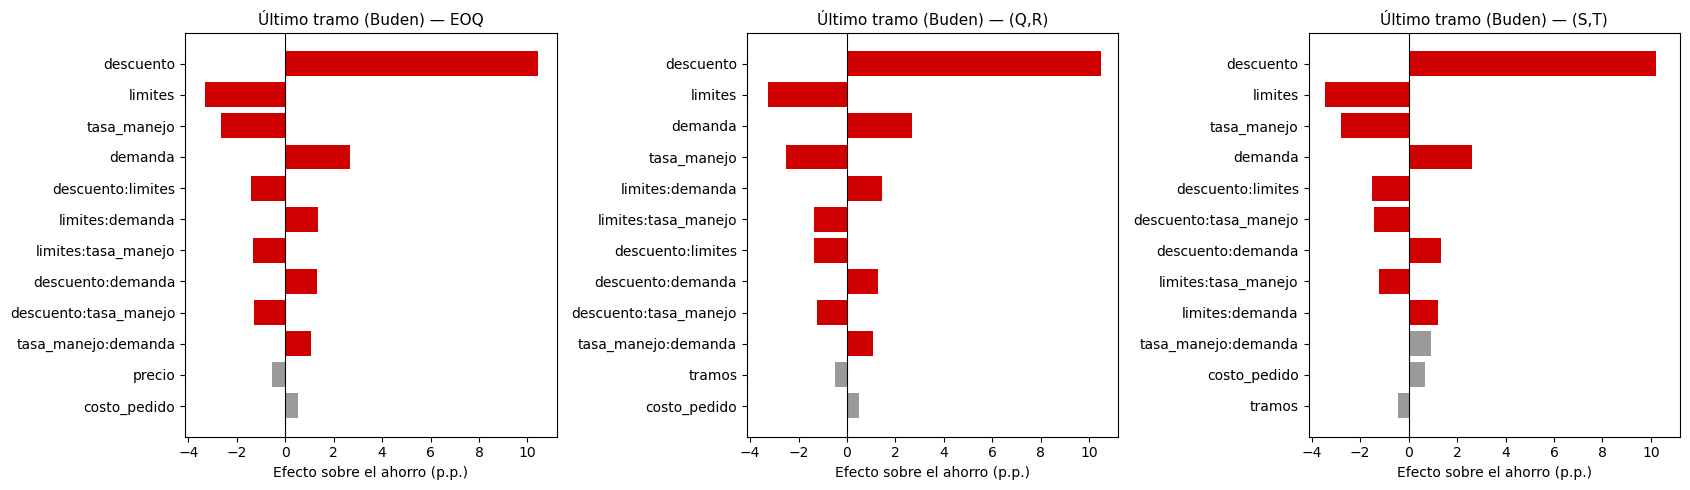

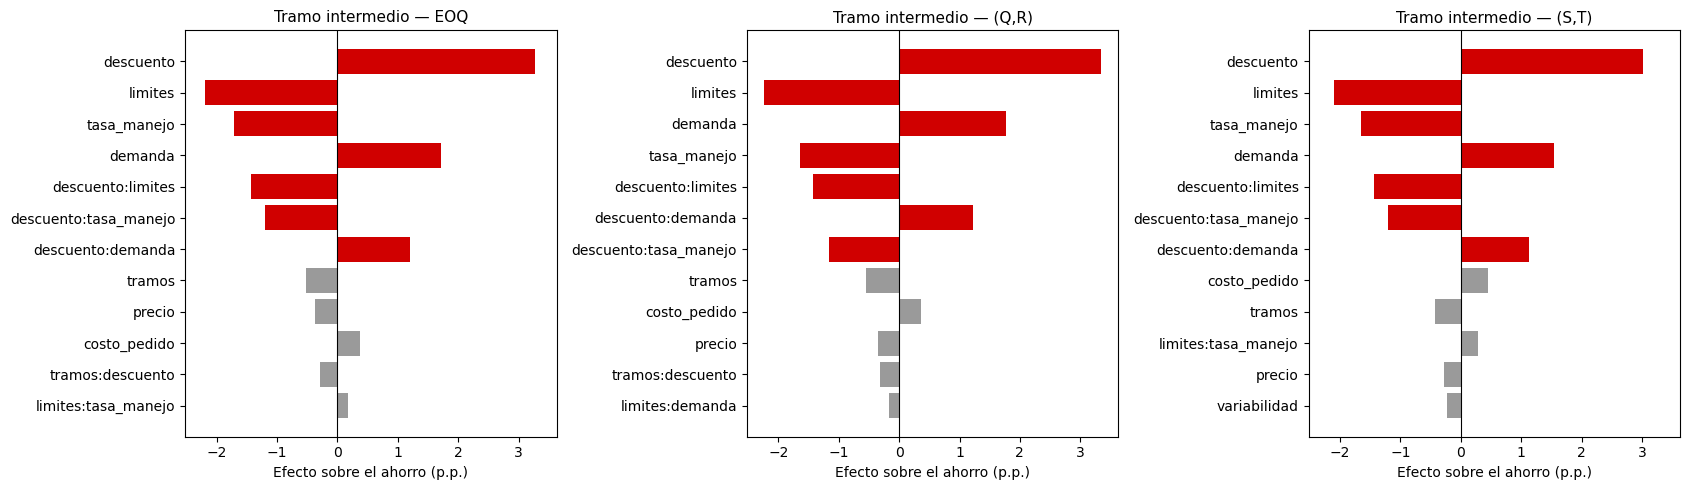

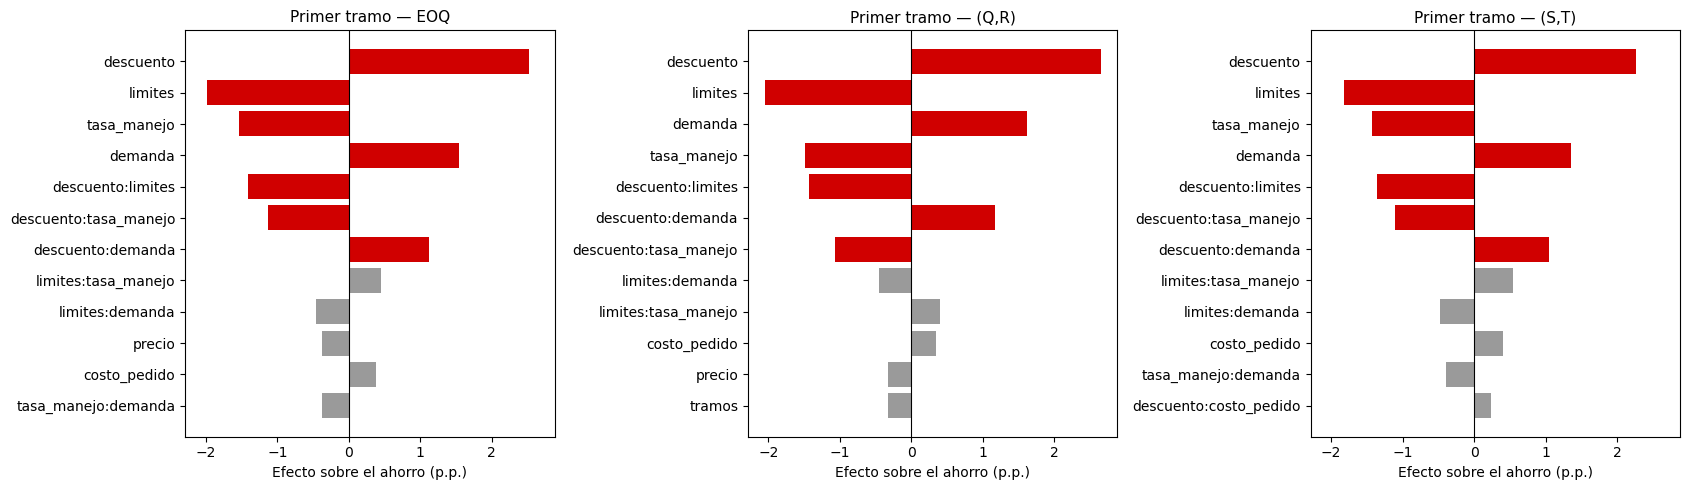

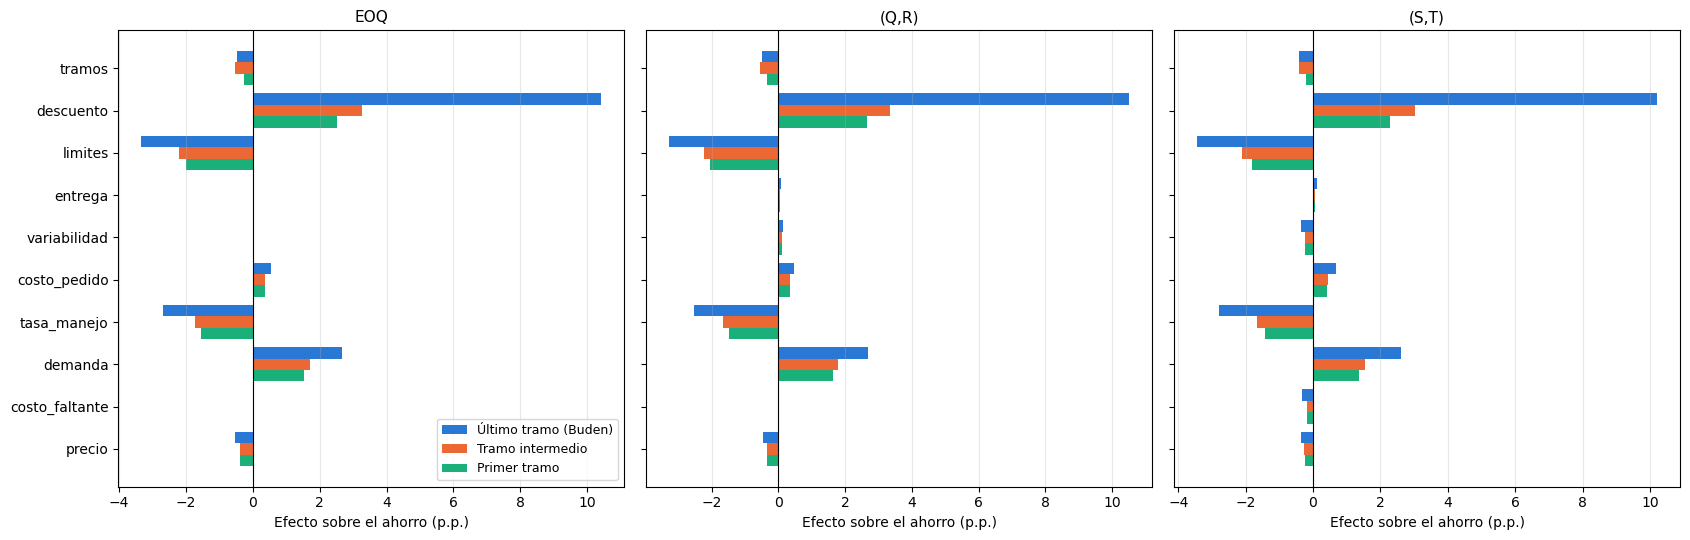

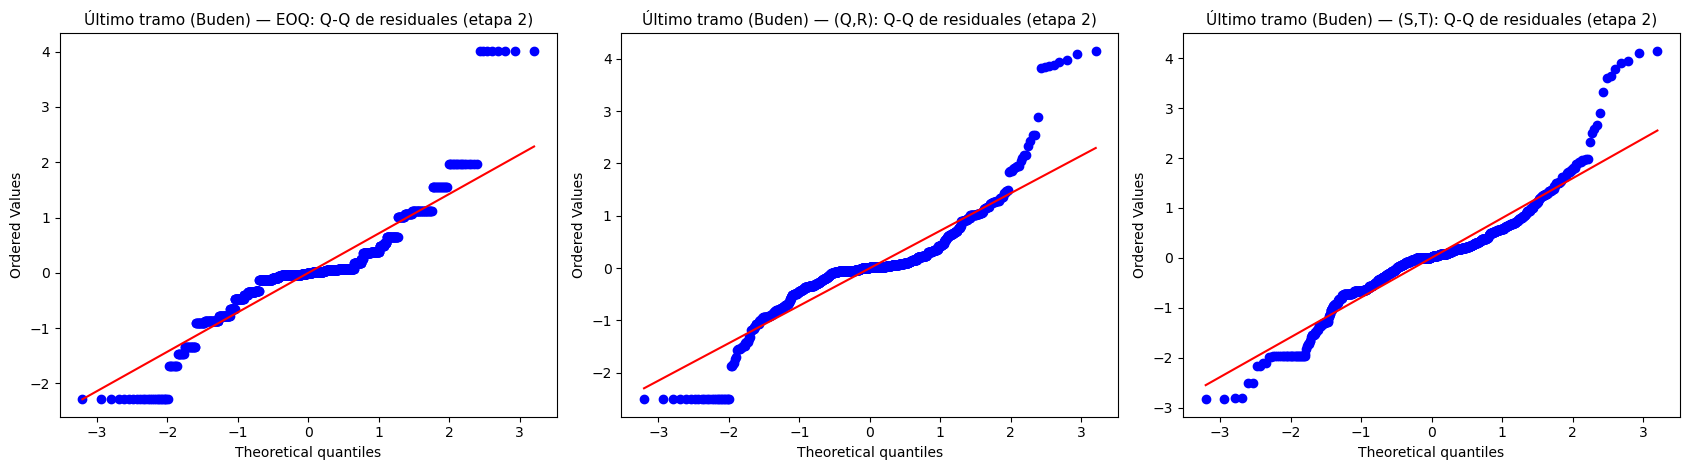

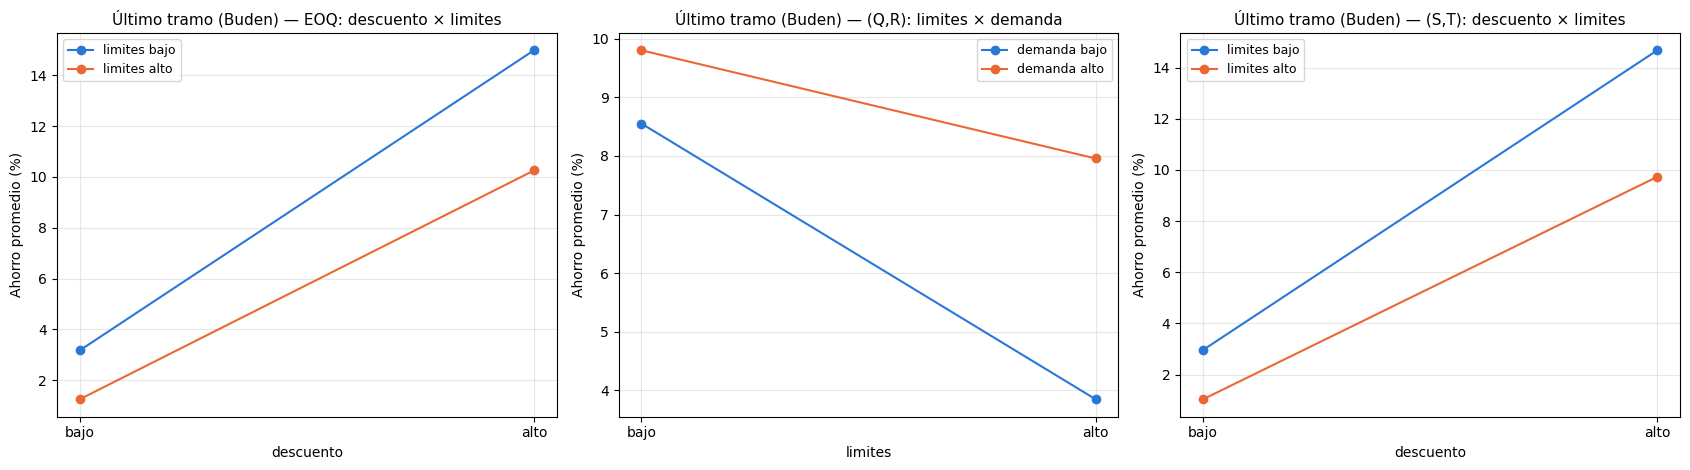

In [10]:
for b, base in bases.items():                                            # 1) una figura por base
    figura, ejes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)      # tres modelos lado a lado
    for eje, m in zip(ejes, modelos):                                    # un panel por modelo
        tabla = etapa1[(b, m)][0].head(12)                               # los 12 términos más grandes
        colores = ["#d00000" if abs(e) > 1 else "#9a9a9a" for e in tabla["efecto (p.p.)"]]   # rojo si el efecto es mayor a 1 p.p. (el umbral de importancia)
        eje.barh(range(len(tabla)), tabla["efecto (p.p.)"], color=colores)            # barras horizontales
        eje.set_yticks(range(len(tabla)), tabla.index)                   # nombres de los términos
        eje.invert_yaxis()                                               # el más grande arriba
        eje.axvline(0, color="black", linewidth=0.8)                     # línea del cero
        eje.set_xlabel("Efecto sobre el ahorro (p.p.)")                  # eje x
        eje.set_title(f"{base['nombre']} — {modelos[m]}", fontsize=11)   # título del panel
    plt.tight_layout()                                                   # ajusta márgenes
    plt.savefig(carpeta_sensibilidad / f"etapa1_{b}.png", dpi=200)       # guarda la imagen
    plt.show()                                                           # muestra la figura

figura, ejes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)        # 2) comparación de las bases
colores_base = {"buden": "#2a78d6", "intermedio": "#eb6834", "primero": "#1baf7a"}   # un color por base
for eje, m in zip(ejes, modelos):                                        # un panel por modelo
    for k, (b, base) in enumerate(bases.items()):                        # una barra por base
        valores = etapa1[(b, m)][0]["efecto (p.p.)"].reindex(factores)   # efecto de cada factor
        eje.barh(np.arange(len(factores)) + (k - 1) * 0.27, valores, height=0.27,   # barras agrupadas por factor
                 color=colores_base[b], label=base["nombre"])            # color de la base
    eje.set_yticks(range(len(factores)), factores)                       # nombres de los factores
    eje.invert_yaxis()                                                   # el primero arriba
    eje.axvline(0, color="black", linewidth=0.8)                         # línea del cero
    eje.set_xlabel("Efecto sobre el ahorro (p.p.)")                      # eje x
    eje.set_title(modelos[m], fontsize=11)                               # título del panel
    eje.grid(axis="x", alpha=0.3)                                        # cuadrícula suave
ejes[0].legend(fontsize=9)                                               # leyenda
plt.tight_layout()                                                       # ajusta márgenes
plt.savefig(carpeta_sensibilidad / "comparacion_bases.png", dpi=200)     # guarda la imagen
plt.show()                                                               # muestra la figura

figura, ejes = plt.subplots(1, 3, figsize=(17, 4.8))                     # 3) Q-Q de Buden
for eje, m in zip(ejes, modelos):                                        # un panel por modelo
    stats.probplot(etapa2[("buden", m)][2].resid, dist="norm", plot=eje) # gráfica Q-Q (igual que en la clase)
    eje.set_title(f"Último tramo (Buden) — {modelos[m]}: Q-Q de residuales (etapa 2)", fontsize=11)   # título
plt.tight_layout()                                                       # ajusta márgenes
plt.savefig(carpeta_sensibilidad / "qq_buden.png", dpi=200)              # guarda la imagen
plt.show()                                                               # muestra la figura

figura, ejes = plt.subplots(1, 3, figsize=(17, 4.8))                     # 4) interacción más fuerte de Buden
for eje, m in zip(ejes, modelos):                                        # un panel por modelo
    efectos = etapa2[("buden", m)][0]                                    # efectos de la etapa 2
    dobles = efectos[efectos.index.str.count(":") == 1]                  # solo interacciones de a dos
    f1, f2 = dobles.index[0].split(":")                                  # los dos factores de la más fuerte
    tabla = resultados["buden"]                                          # corridas de Buden
    for nivel2, color in [(-1, "#2a78d6"), (1, "#eb6834")]:              # una línea por nivel del segundo factor
        medias = [tabla[(tabla[f1] == n1) & (tabla[f2] == nivel2)][f"ahorro_{m}"].mean() for n1 in (-1, 1)]   # ahorro promedio
        eje.plot(["bajo", "alto"], medias, "o-", color=color, label=f"{f2} {'bajo' if nivel2 == -1 else 'alto'}")   # línea
    eje.set_xlabel(f1)                                                   # primer factor en el eje x
    eje.set_ylabel("Ahorro promedio (%)")                                # eje y
    eje.set_title(f"Último tramo (Buden) — {modelos[m]}: {f1} × {f2}", fontsize=11)     # título
    eje.legend(fontsize=9)                                               # leyenda
    eje.grid(alpha=0.3)                                                  # cuadrícula suave
plt.tight_layout()                                                       # ajusta márgenes
plt.savefig(carpeta_sensibilidad / "interaccion_buden.png", dpi=200)     # guarda la imagen
plt.show()                                                               # muestra la figura

### 9. Guardar en Excel
Un archivo con, para cada base: los niveles, las 1,024 corridas, los efectos de la etapa 1 y la tabla ANOVA de la etapa 2 de cada modelo.

In [11]:
with pd.ExcelWriter("analisis_sensibilidad.xlsx") as archivo:            # abre el archivo de Excel
    for b, base in bases.items():                                        # una tanda de hojas por base
        niveles = niveles_de_una_base_devuelve_diccionario(base)         # niveles de la base
        pd.DataFrame([(f, str(v[0]), str(v[1])) for f, v in niveles.items()],   # tabla de niveles
                     columns=["factor", "bajo (-1)", "alto (+1)"]).to_excel(archivo, sheet_name=f"niveles_{b}", index=False)   # hoja de niveles
        resultados[b].to_excel(archivo, sheet_name=f"corridas_{b}", index=False)   # las 1,024 corridas
        for m in modelos:                                                # un par de hojas por modelo
            etapa1[(b, m)][0].to_excel(archivo, sheet_name=f"etapa1_{b}_{m}")       # efectos de la etapa 1
            etapa2[(b, m)][1].to_excel(archivo, sheet_name=f"etapa2_{b}_{m}")       # ANOVA de la etapa 2
print("Guardado: analisis_sensibilidad.xlsx")                            # aviso

Guardado: analisis_sensibilidad.xlsx
